# Machine Maintenance Prediction — Data Cleaning

Run this notebook **one cell at a time**, from top to bottom (Shift+Enter in VS Code), using the `.venv` kernel.

**Before starting:** make sure `proj_machine_readings.csv` is in the same folder as this notebook.

This notebook preserves the original vibration field, creates `vibration_abs`, flags missing temperatures before imputing them with each machine's median, and does not remove statistical outliers.

## Step 1 — Import the libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

## Step 2 — Set the path to the original CSV

In [ ]:
# The CSV is in the same folder as this notebook
input_file = "proj_machine_readings.csv"

print("Using file:", input_file)

Using file: proj_machine_readings.csv


## Step 3 — Load the dataset

In [ ]:
df = pd.read_csv(input_file)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (100000, 13)


,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.65,79.96,3.73,2.16,1,0,106,Normal,0.0,0
1,2025-01-01 00:01:00,29,68.19,57.28,35.94,3.64,0.69,1,0,320,Normal,0.0,0
2,2025-01-01 00:02:00,15,98.94,50.20,72.06,1.00,2.49,1,1,19,Normal,1.0,1
3,2025-01-01 00:03:00,43,90.91,37.65,30.34,3.15,4.96,1,1,10,Normal,1.0,1
4,2025-01-01 00:04:00,8,72.32,40.69,56.71,2.68,0.63,2,0,65,Vibration Issue,0.0,1


## Step 4 — Inspect the column names and data types

In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
df.info()

Column names:
['timestamp', 'machine_id', 'temperature', 'vibration', 'humidity', 'pressure', 'energy_consumption', 'machine_status', 'anomaly_flag', 'predicted_remaining_life', 'failure_type', 'downtime_risk', 'maintenance_required']

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   timestamp                 100000 non-null  str    
 1   machine_id                100000 non-null  int64  
 2   temperature               86000 non-null   float64
 3   vibration                 100000 non-null  float64
 4   humidity                  100000 non-null  float64
 5   pressure                  100000 non-null  float64
 6   energy_consumption        100000 non-null  float64
 7   machine_status            100000 non-null  int64  
 8   anomaly_flag              100000 non-null  int64  
 9   predicted_remaining_life  100000

## Step 5 — Generate a statistical summary

In [ ]:
display(df.describe(include="all"))

,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
count,100000,100000.000000,86000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000,100000.000000,100000.000000
unique,100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN
top,2025-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Normal,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,91899,NaN,NaN
mean,NaN,25.499330,75.034410,43.324232,54.995401,3.000405,2.747064,1.002050,0.089160,234.269160,NaN,0.089155,0.196970
std,NaN,14.389439,10.036257,29.134306,14.437960,1.152399,1.297865,0.446193,0.284976,150.063062,NaN,0.284961,0.397711
min,NaN,1.000000,35.550000,-106.980000,30.000000,1.000000,0.500000,0.000000,0.000000,1.000000,NaN,0.000000,0.000000
25%,NaN,13.000000,68.280000,37.220000,42.520000,2.000000,1.630000,1.000000,0.000000,97.000000,NaN,0.000000,0.000000
50%,NaN,25.000000,75.090000,48.635000,54.980000,3.010000,2.740000,1.000000,0.000000,230.000000,NaN,0.000000,0.000000
75%,NaN,38.000000,81.780000,59.250000,67.500000,4.000000,3.870000,1.000000,0.000000,365.000000,NaN,0.000000,0.000000


## Step 6 — Check missing values before cleaning

In [ ]:
missing_before = df.isnull().sum()

missing_percentage = (missing_before / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing values": missing_before,
    "Missing percentage": missing_percentage.round(2)
})

display(missing_summary)

,Missing values,Missing percentage
timestamp,0,0.0
machine_id,0,0.0
temperature,14000,14.0
vibration,0,0.0
humidity,0,0.0
pressure,0,0.0
energy_consumption,0,0.0
machine_status,0,0.0
anomaly_flag,0,0.0
predicted_remaining_life,0,0.0


## Step 7 — Create a temperature missing indicator

Create this indicator **before** filling missing temperatures:
- `1` means the original temperature was missing.
- `0` means the original temperature was present.

This preserves information about missing sensor readings.

In [ ]:
df["temperature_missing"] = df["temperature"].isnull().astype(int)

print("Temperature missing indicator:")
print(df["temperature_missing"].value_counts())

Temperature missing indicator:
temperature_missing
0    86000
1    14000
Name: count, dtype: int64


## Step 8 — Impute temperature using each machine's median

In [ ]:
# Fill missing temperature values with the median temperature
# of the corresponding machine.
df["temperature"] = df.groupby("machine_id")["temperature"].transform(
    lambda machine_values: machine_values.fillna(machine_values.median())
)

# Fallback: if a machine has no valid temperature readings at all,
# fill any remaining missing values with the overall median.
df["temperature"] = df["temperature"].fillna(df["temperature"].median())

print("Missing temperatures after imputation:",
      df["temperature"].isnull().sum())

Missing temperatures after imputation: 0


## Step 9 — Preserve vibration and create absolute vibration

The vibration unit/sign convention has not been confirmed. Keep the original `vibration` column unchanged and create a separate magnitude field, `vibration_abs`.

Do not delete negative vibration readings at this stage.

In [ ]:
df["vibration_abs"] = df["vibration"].abs()

print("Negative values in original vibration:",
      (df["vibration"] < 0).sum())

display(df[["vibration", "vibration_abs"]].head(10))

Negative values in original vibration: 6703


,vibration,vibration_abs
0,-28.65,28.65
1,57.28,57.28
2,50.20,50.20
3,37.65,37.65
4,40.69,40.69
5,38.38,38.38
6,40.70,40.70
7,56.52,56.52
8,24.98,24.98
9,49.29,49.29


## Step 10 — Examine absolute vibration by failure type

In [ ]:
vibration_by_failure = df.groupby(
    "failure_type", observed=False
)["vibration_abs"].agg(["count", "median", "mean", "max"])

display(vibration_by_failure)

,count,median,mean,max
failure_type,,,,
Electrical Fault,1014,48.715,48.969763,95.02
Normal,91899,49.980,50.026809,113.80
Overheating,1989,50.030,49.835636,103.50
Pressure Drop,1969,49.760,49.883763,91.28
Vibration Issue,3129,50.220,50.228626,109.71


**Interpretation note:** The vibration field has shown almost no relationship with `Vibration Issue`. Treat it as a questionable sensor and investigate its usefulness during EDA and model evaluation. Do not assume that `vibration_abs` is automatically a strong predictor.

## Step 11 — Check exact duplicate rows

In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


## Step 12 — Check repeated readings for the same machine and timestamp

In [ ]:
repeated_machine_time = df.duplicated(
    subset=["machine_id", "timestamp"]
).sum()

print("Repeated machine_id + timestamp combinations:",
      repeated_machine_time)

# Do not automatically remove these rows.
# Investigate them first if any are found.

Repeated machine_id + timestamp combinations: 0


## Step 13 — Remove exact duplicate rows, if any

In [ ]:
# Remove only exact duplicate rows.
# This does not remove repeated machine-time combinations unless
# the entire row is identical.
df = df.drop_duplicates().copy()

print("Dataset shape after exact duplicate check:", df.shape)

Dataset shape after exact duplicate check: (100000, 15)


## Step 14 — Convert timestamp into datetime format

In [ ]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print("Timestamp data type:", df["timestamp"].dtype)
print("Invalid or missing timestamps:", df["timestamp"].isnull().sum())

Timestamp data type: datetime64[us]
Invalid or missing timestamps: 0


## Step 15 — Validate categorical values

In [ ]:
print("Machine status values:")
print(df["machine_status"].value_counts(dropna=False))

print("\nAnomaly flag values:")
print(df["anomaly_flag"].value_counts(dropna=False))

print("\nFailure type values:")
print(df["failure_type"].value_counts(dropna=False))

print("\nMaintenance required values:")
print(df["maintenance_required"].value_counts(dropna=False))

Machine status values:
machine_status
1    80091
2    10057
0     9852
Name: count, dtype: int64

Anomaly flag values:
anomaly_flag
0    91084
1     8916
Name: count, dtype: int64

Failure type values:
failure_type
Normal              91899
Vibration Issue      3129
Overheating          1989
Pressure Drop        1969
Electrical Fault     1014
Name: count, dtype: int64

Maintenance required values:
maintenance_required
0    80303
1    19697
Name: count, dtype: int64


## Step 16 — Check for unexpected category labels

In [ ]:
expected_values = {
    "machine_status": {0, 1, 2},
    "anomaly_flag": {0, 1},
    "failure_type": {
        "Normal",
        "Vibration Issue",
        "Overheating",
        "Pressure Drop",
        "Electrical Fault"
    },
    "maintenance_required": {0, 1}
}

for column, allowed_values in expected_values.items():
    observed_values = set(df[column].dropna().unique())
    unexpected_values = observed_values - allowed_values

    print(f"{column} - unexpected values: {unexpected_values}")

machine_status - unexpected values: set()
anomaly_flag - unexpected values: set()
failure_type - unexpected values: set()
maintenance_required - unexpected values: set()


## Step 17 — Inspect the target variable distribution

maintenance_required
0    80303
1    19697
Name: count, dtype: int64


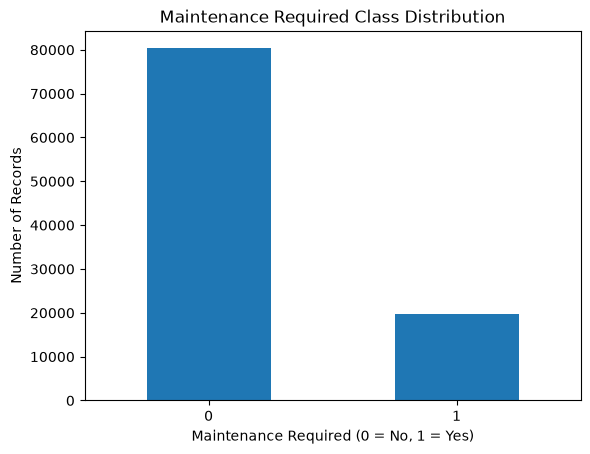

In [ ]:
target_counts = df["maintenance_required"].value_counts().sort_index()

print(target_counts)

target_counts.plot(
    kind="bar",
    title="Maintenance Required Class Distribution",
    xlabel="Maintenance Required (0 = No, 1 = Yes)",
    ylabel="Number of Records"
)

plt.xticks(rotation=0)
plt.show()

## Step 18 — Inspect sensor distributions using boxplots

Boxplots help identify unusual readings. In this project, extreme readings may indicate machine faults.

**Do not automatically delete or cap high values just because they fall outside statistical outlier boundaries.**

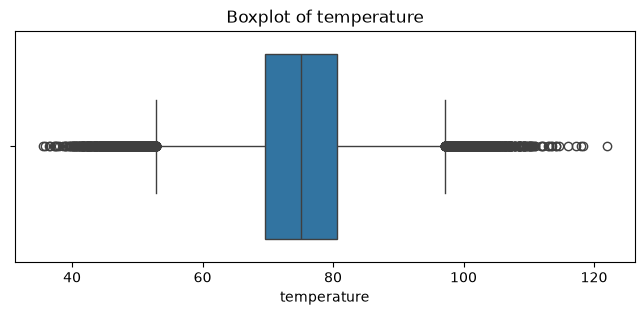

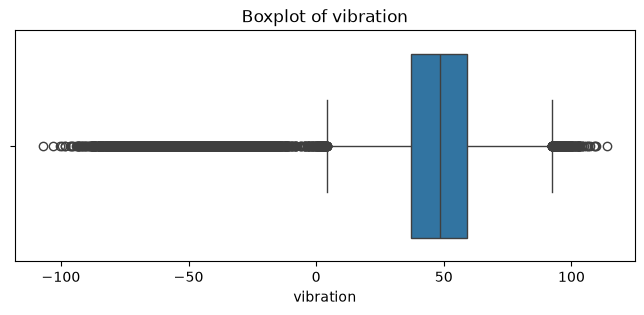

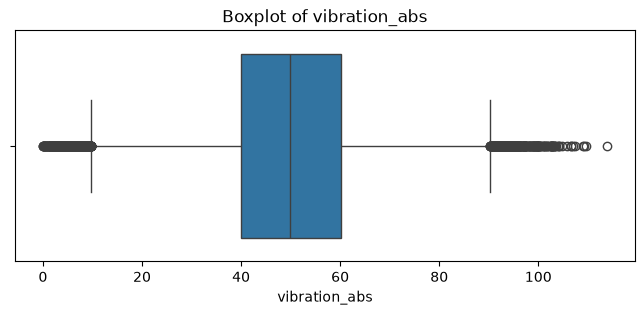

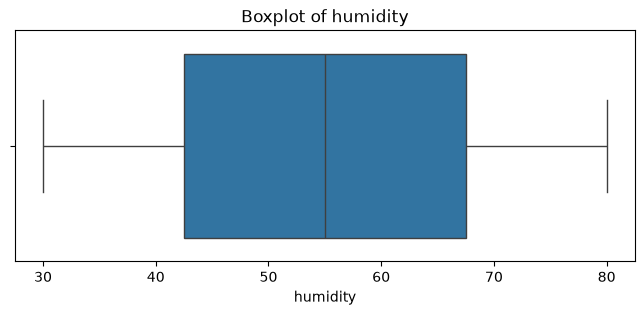

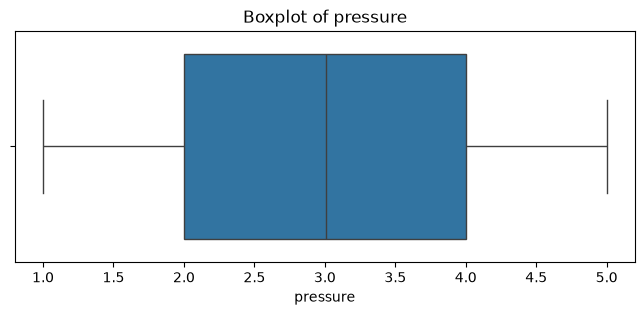

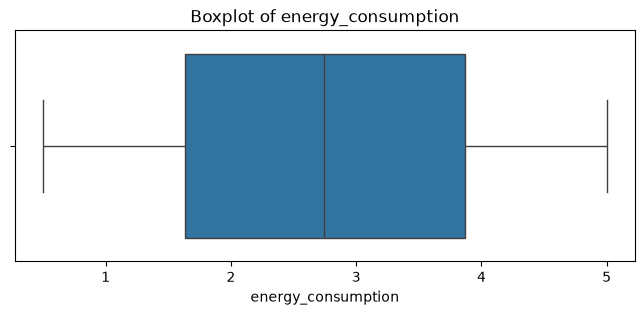

In [ ]:
sensor_columns = [
    "temperature",
    "vibration",
    "vibration_abs",
    "humidity",
    "pressure",
    "energy_consumption"
]

for column in sensor_columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.show()

## Step 19 — Count statistical outliers for investigation only

In [ ]:
# The IQR fences are used only to flag unusual observations.
# No rows or values are removed or changed in this step.

outlier_results = []

for column in sensor_columns:
    values = df[column].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outlier_count = (
        (values < lower_fence) | (values > upper_fence)
    ).sum()

    outlier_results.append({
        "Column": column,
        "Lower fence": lower_fence,
        "Upper fence": upper_fence,
        "Values outside fences": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary.round(3))

,Column,Lower fence,Upper fence,Values outside fences
0,temperature,52.880,97.200,2313
1,vibration,4.175,92.295,6999
2,vibration_abs,9.775,90.295,714
3,humidity,5.050,104.970,0
4,pressure,-1.000,7.000,0
5,energy_consumption,-1.730,7.230,0


## Step 20 — Final missing-value check

In [ ]:
print("Missing values after cleaning:")
display(df.isnull().sum())

print("Final dataset shape:", df.shape)

Missing values after cleaning:


timestamp                   0
machine_id                  0
temperature                 0
vibration                   0
humidity                    0
pressure                    0
energy_consumption          0
machine_status              0
anomaly_flag                0
predicted_remaining_life    0
failure_type                0
downtime_risk               0
maintenance_required        0
temperature_missing         0
vibration_abs               0
dtype: int64

Final dataset shape: (100000, 15)


## Step 21 — Final duplicate check

In [ ]:
print("Final exact duplicate count:", df.duplicated().sum())

Final exact duplicate count: 0


## Step 22 — Final check of the new columns

In [ ]:
print("Number of originally missing temperatures:",
      df["temperature_missing"].sum())

print("Missing temperature values remaining:",
      df["temperature"].isnull().sum())

print("Missing vibration_abs values:",
      df["vibration_abs"].isnull().sum())

display(df[[
    "machine_id",
    "temperature",
    "temperature_missing",
    "vibration",
    "vibration_abs"
]].head(10))

Number of originally missing temperatures: 14000
Missing temperature values remaining: 0
Missing vibration_abs values: 0


,machine_id,temperature,temperature_missing,vibration,vibration_abs
0,39,74.46,1,-28.65,28.65
1,29,68.19,0,57.28,57.28
2,15,98.94,0,50.20,50.20
3,43,90.91,0,37.65,37.65
4,8,72.32,0,40.69,40.69
5,21,70.88,0,38.38,38.38
6,39,73.05,0,40.70,40.70
7,19,90.00,0,56.52,56.52
8,23,74.79,1,24.98,24.98
9,11,55.33,0,49.29,49.29


## Step 23 — Save the cleaned dataset

This saves a new CSV file. Your original dataset remains unchanged.

In [ ]:
output_file = "cleaned_machine_readings.csv"

df.to_csv(output_file, index=False)

print("Cleaned dataset saved as:", output_file)

## Step 24 — Confirm where the cleaned CSV was saved

In [ ]:
print("Cleaned file location:", Path(output_file).resolve())

## Important notes for the modelling stage

1. `temperature_missing` records which temperature readings were originally missing.
2. `vibration` is retained as supplied; `vibration_abs` is a separate absolute-value feature.
3. High absolute readings and statistical outliers have not been removed.
4. Treat vibration as a questionable sensor and evaluate its usefulness rather than assuming it predicts `Vibration Issue`.
5. Investigate derived columns for target leakage before using them as model predictors.
6. For rigorous model evaluation, fit preprocessing using training data only. The machine-median imputation above is suitable for this initial cleaning/EDA exercise; later, reproduce imputation within the training pipeline to avoid test-data leakage.
